# 구글드라이브 연결하기

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# 1. 훈련데이터 불러오기

In [ ]:
import os
import pandas as pd

In [ ]:
## 디렉토리 확인
dirname = os.path.join('drive', 'MyDrive', 'dacon','open')
print(dirname)

drive/MyDrive/dacon/open


In [ ]:
## 파일 경로 확인
filepath_train = os.path.join(dirname, 'train.csv')
print(os.path.exists(filepath_train))

True


## 1.1. CSV 파일을 Pandas 데이터프레임으로 불러오기

In [ ]:
df_raw = pd.read_csv(filepath_train)

In [ ]:
## 훈련데이터 크기 확인
df_raw.shape

(87159, 16)

In [ ]:
## 훈련데이터 상위 5개 살펴보기
df_raw.head()

,ID,Age,Gender,Country,Race,Family_Background,Radiation_History,Iodine_Deficiency,Smoke,Weight_Risk,Diabetes,Nodule_Size,TSH_Result,T4_Result,T3_Result,Cancer
0,TRAIN_00000,80,M,CHN,ASN,Positive,Exposed,Sufficient,Non-Smoker,Not Obese,No,0.650355,2.784735,6.744603,2.575820,1
1,TRAIN_00001,37,M,NGA,ASN,Positive,Unexposed,Sufficient,Smoker,Obese,No,2.950430,0.911624,7.303305,2.505317,1
2,TRAIN_00002,71,M,CHN,MDE,Positive,Unexposed,Sufficient,Non-Smoker,Not Obese,Yes,2.200023,0.717754,11.137459,2.381080,0
3,TRAIN_00003,40,F,IND,HSP,Negative,Unexposed,Sufficient,Non-Smoker,Obese,No,3.370796,6.846380,10.175254,0.753023,0
4,TRAIN_00004,53,F,CHN,CAU,Negative,Unexposed,Sufficient,Non-Smoker,Not Obese,No,4.230048,0.439519,7.194450,0.569356,1


# 변수 시각화

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

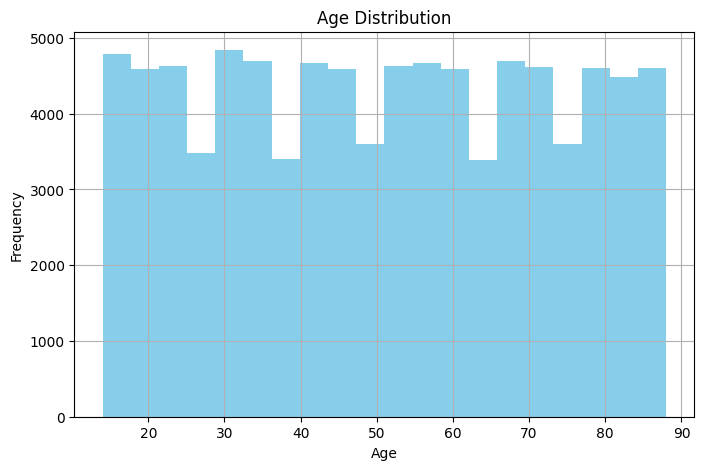

In [ ]:
#나이 분포 히스토그램
plt.figure(figsize=(8, 5))
df_raw['Age'].plot.hist(bins=20, color='skyblue')
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

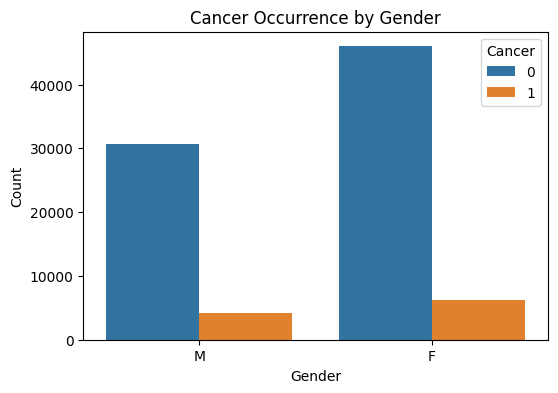

In [ ]:
#성별에 따른 암 발생 비율(막대그래프)
plt.figure(figsize=(6, 4))
sns.countplot(x='Gender', hue='Cancer', data=df_raw)
plt.title('Cancer Occurrence by Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

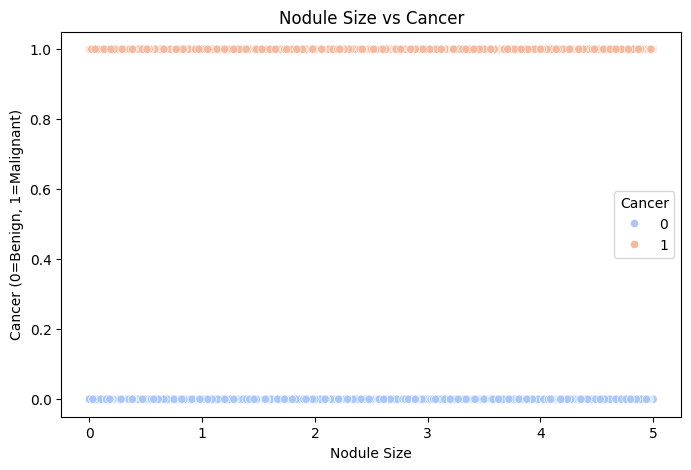

In [ ]:
#결절 크기와 암 발생 관계(산점도)
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Nodule_Size', y='Cancer', data=df_raw, hue='Cancer', palette='coolwarm')
plt.title('Nodule Size vs Cancer')
plt.xlabel('Nodule Size')
plt.ylabel('Cancer (0=Benign, 1=Malignant)')
plt.show()

## 범주형 데이터 시각화

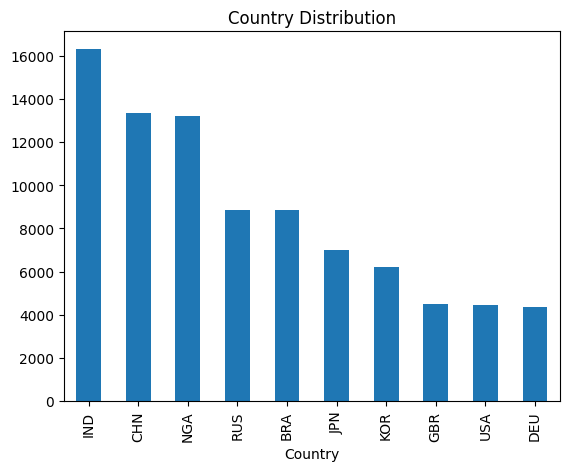

In [ ]:
#Country
df_raw['Country'].value_counts().plot.bar(title='Country Distribution')
plt.show()

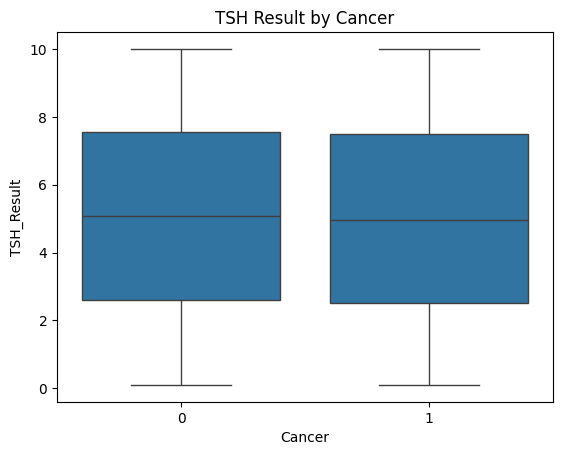

In [ ]:
#Cancer에 따라 'TSH_Result'(TSH 호르몬 검사 결과)의 분포
sns.boxplot(x='Cancer', y='TSH_Result', data=df_raw)
plt.title('TSH Result by Cancer')
plt.show()

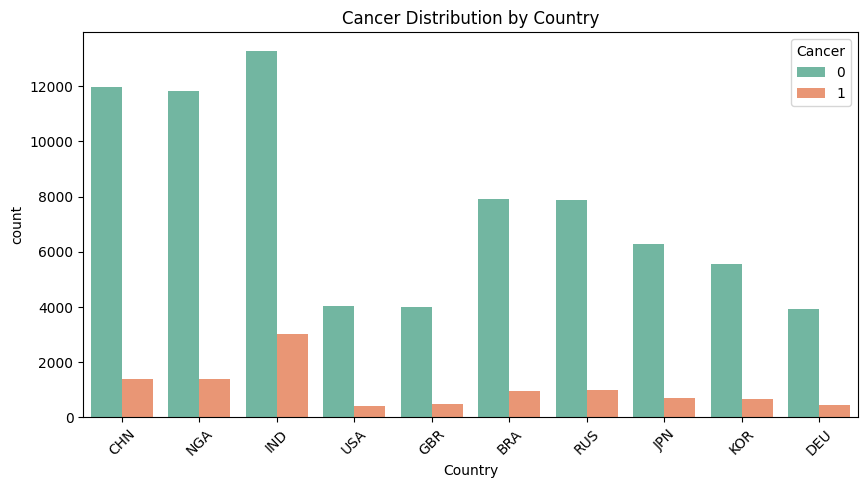

In [ ]:
#Country(국적)별 암 발생 분포 (countplot + hue)
plt.figure(figsize=(10, 5))
sns.countplot(x='Country', hue='Cancer', data=df_raw, palette='Set2')
plt.title('Cancer Distribution by Country')
plt.xticks(rotation=45)
plt.show()

<ipython-input-15-3370158319>:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Race', y='Cancer', data=race_cancer, palette='Set1')


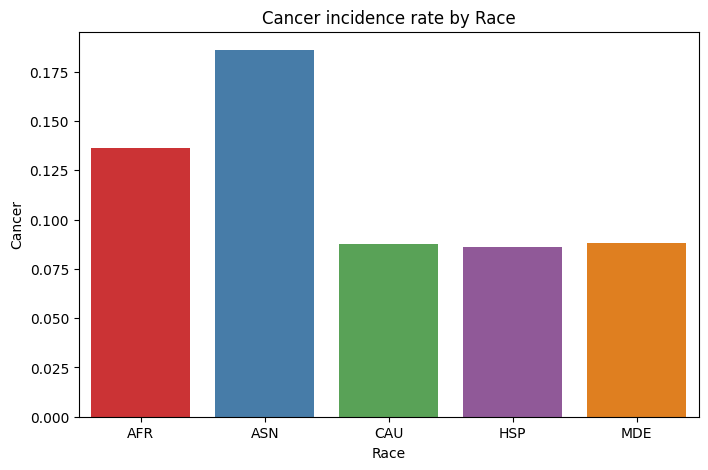

In [ ]:
#Race(인종)별 암 발생 비율 (비율 barplot)
race_cancer = df_raw.groupby('Race')['Cancer'].mean().reset_index()
plt.figure(figsize=(8, 5))
sns.barplot(x='Race', y='Cancer', data=race_cancer, palette='Set1')
plt.title('Cancer incidence rate by Race')
plt.show()

<ipython-input-16-843148836>:3: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='Family_Background', y='Cancer', data=df_raw, ci=None, palette='Pastel1')
<ipython-input-16-843148836>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Family_Background', y='Cancer', data=df_raw, ci=None, palette='Pastel1')


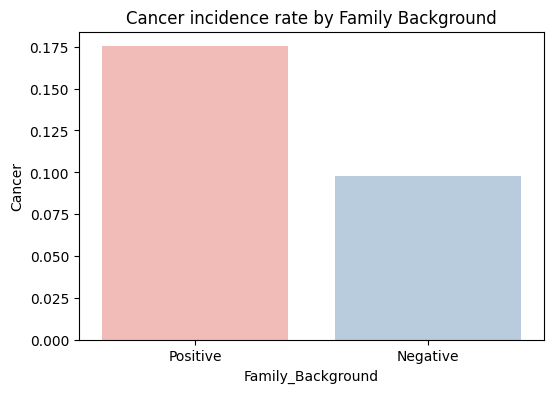

In [ ]:
#Family_Background(가족력)별 암 발생 비율
plt.figure(figsize=(6, 4))
sns.barplot(x='Family_Background', y='Cancer', data=df_raw, ci=None, palette='Pastel1')
plt.title('Cancer incidence rate by Family Background')
plt.show()

<ipython-input-17-1966480230>:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Smoke', y='Cancer', data=df_raw, palette='muted')


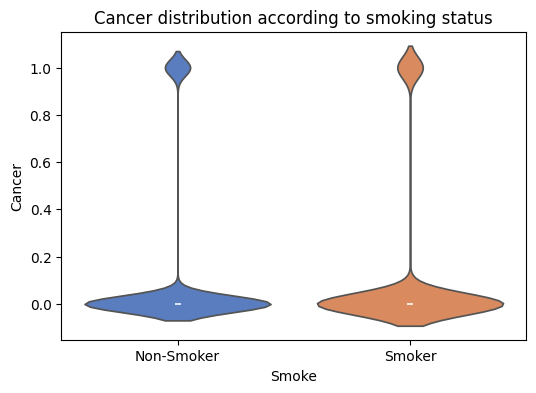

In [ ]:
#Smoke(흡연 여부)와 암 발생 분포 (violin plot)
plt.figure(figsize=(6, 4))
sns.violinplot(x='Smoke', y='Cancer', data=df_raw, palette='muted')
plt.title('Cancer distribution according to smoking status')
plt.show()

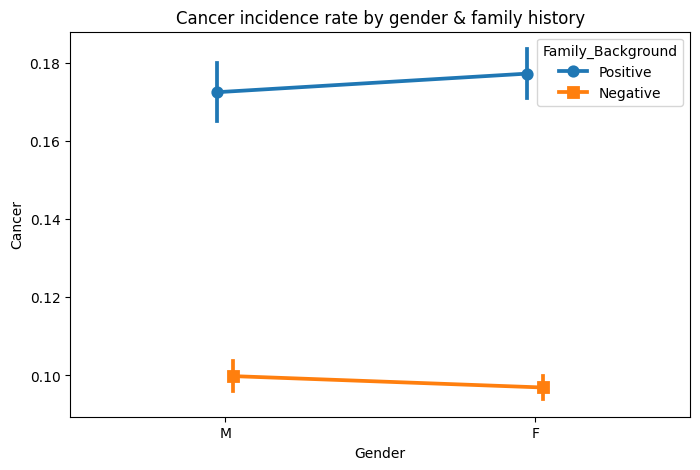

In [ ]:
#성별과 가족력 조합별 암 발생 비율 (pointplot)
plt.figure(figsize=(8, 5))
sns.pointplot(x='Gender', y='Cancer', hue='Family_Background', data=df_raw, dodge=True, markers=['o', 's'])
plt.title('Cancer incidence rate by gender & family history')
plt.show()

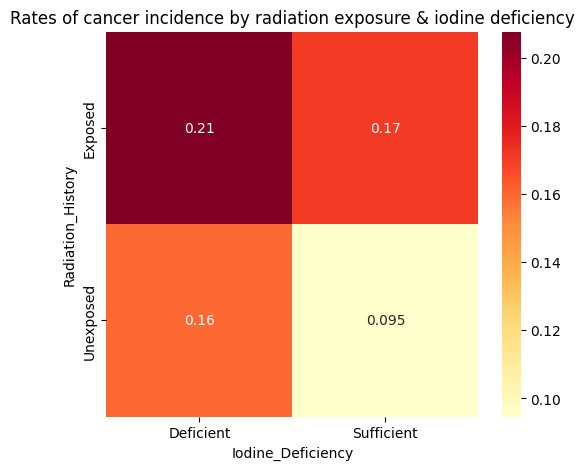

In [ ]:
#Radiation_History(방사선 노출)와 Iodine_Deficiency(요오드 결핍) 조합별 암 발생 빈도 (heatmap)
pivot = pd.crosstab(df_raw['Radiation_History'], df_raw['Iodine_Deficiency'], values=df_raw['Cancer'], aggfunc='mean')
plt.figure(figsize=(6, 5))
sns.heatmap(pivot, annot=True, cmap='YlOrRd')
plt.title('Rates of cancer incidence by radiation exposure & iodine deficiency')
plt.show()

# 2. 훈련데이터 전처리하기

## 2.1. 특징값(X), 목표값(y) 추출하기

In [ ]:
## 목표값 추출
df_y = df_raw.loc[:,"Cancer"]

In [ ]:
## 특징값 추출
df_X = df_raw.drop("Cancer", axis=1)

In [ ]:
## 추출된 데이터 확인
print("df_X.shape:", df_X.shape)
print("df_y.shape:", df_y.shape)

df_X.shape: (87159, 15)
df_y.shape: (87159,)


In [ ]:
## 특징값 상위 5개 살펴보기
df_X.head()

,ID,Age,Gender,Country,Race,Family_Background,Radiation_History,Iodine_Deficiency,Smoke,Weight_Risk,Diabetes,Nodule_Size,TSH_Result,T4_Result,T3_Result
0,TRAIN_00000,80,M,CHN,ASN,Positive,Exposed,Sufficient,Non-Smoker,Not Obese,No,0.650355,2.784735,6.744603,2.575820
1,TRAIN_00001,37,M,NGA,ASN,Positive,Unexposed,Sufficient,Smoker,Obese,No,2.950430,0.911624,7.303305,2.505317
2,TRAIN_00002,71,M,CHN,MDE,Positive,Unexposed,Sufficient,Non-Smoker,Not Obese,Yes,2.200023,0.717754,11.137459,2.381080
3,TRAIN_00003,40,F,IND,HSP,Negative,Unexposed,Sufficient,Non-Smoker,Obese,No,3.370796,6.846380,10.175254,0.753023
4,TRAIN_00004,53,F,CHN,CAU,Negative,Unexposed,Sufficient,Non-Smoker,Not Obese,No,4.230048,0.439519,7.194450,0.569356


In [ ]:
## 클래스 분포 살펴보기
df_y.value_counts()

,count
Cancer,
0,76700
1,10459


## 2.2. 범주형 데이터(categorical)를 One-hot 벡터로 변환하기

In [ ]:
import sklearn; print(sklearn.__version__)

1.6.1


In [ ]:
from sklearn.preprocessing import OneHotEncoder

In [ ]:
categorical_columns = ['Gender', 'Country', 'Race', 'Family_Background', 'Radiation_History', 'Iodine_Deficiency', 'Smoke', 'Weight_Risk', 'Diabetes']
enc = OneHotEncoder().fit(df_X.loc[:,categorical_columns])

In [ ]:
enc.categories_

[array(['F', 'M'], dtype=object),
 array(['BRA', 'CHN', 'DEU', 'GBR', 'IND', 'JPN', 'KOR', 'NGA', 'RUS',
        'USA'], dtype=object),
 array(['AFR', 'ASN', 'CAU', 'HSP', 'MDE'], dtype=object),
 array(['Negative', 'Positive'], dtype=object),
 array(['Exposed', 'Unexposed'], dtype=object),
 array(['Deficient', 'Sufficient'], dtype=object),
 array(['Non-Smoker', 'Smoker'], dtype=object),
 array(['Not Obese', 'Obese'], dtype=object),
 array(['No', 'Yes'], dtype=object)]

In [ ]:
df_X.loc[:,categorical_columns].shape

(87159, 9)

In [ ]:
enc.transform(df_X.loc[:,categorical_columns]).shape

(87159, 29)

In [ ]:
enc.get_feature_names_out(categorical_columns)

array(['Gender_F', 'Gender_M', 'Country_BRA', 'Country_CHN',
       'Country_DEU', 'Country_GBR', 'Country_IND', 'Country_JPN',
       'Country_KOR', 'Country_NGA', 'Country_RUS', 'Country_USA',
       'Race_AFR', 'Race_ASN', 'Race_CAU', 'Race_HSP', 'Race_MDE',
       'Family_Background_Negative', 'Family_Background_Positive',
       'Radiation_History_Exposed', 'Radiation_History_Unexposed',
       'Iodine_Deficiency_Deficient', 'Iodine_Deficiency_Sufficient',
       'Smoke_Non-Smoker', 'Smoke_Smoker', 'Weight_Risk_Not Obese',
       'Weight_Risk_Obese', 'Diabetes_No', 'Diabetes_Yes'], dtype=object)

In [ ]:
df_X_category = pd.DataFrame(enc.transform(df_X.loc[:,categorical_columns]).toarray(), columns=enc.get_feature_names_out(categorical_columns))
df_X_category

,Gender_F,Gender_M,Country_BRA,Country_CHN,Country_DEU,Country_GBR,Country_IND,Country_JPN,Country_KOR,Country_NGA,...,Radiation_History_Exposed,Radiation_History_Unexposed,Iodine_Deficiency_Deficient,Iodine_Deficiency_Sufficient,Smoke_Non-Smoker,Smoke_Smoker,Weight_Risk_Not Obese,Weight_Risk_Obese,Diabetes_No,Diabetes_Yes
0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0
1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0
2,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0
3,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0
4,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
87154,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0
87155,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0
87156,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0
87157,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0


## 2.3. 수치형 데이터(numerical) 스케일링 하기

In [ ]:
from sklearn.preprocessing import MinMaxScaler

In [ ]:
numeric_columns = ['Age', 'Nodule_Size', 'TSH_Result', 'T4_Result', 'T3_Result']
scaler = MinMaxScaler().fit(df_X.loc[:,numeric_columns])

In [ ]:
df_X_numeric = pd.DataFrame(scaler.transform(df_X.loc[:,numeric_columns]), columns=numeric_columns)
df_X_numeric

,Age,Nodule_Size,TSH_Result,T4_Result,T3_Result
0,0.891892,0.130071,0.271185,0.299280,0.691940
1,0.310811,0.590086,0.081982,0.373774,0.668439
2,0.770270,0.440005,0.062399,0.884995,0.627027
3,0.351351,0.674159,0.681453,0.756701,0.084341
4,0.527027,0.846010,0.034295,0.359260,0.023119
...,...,...,...,...,...
87154,0.689189,0.102160,0.372410,0.045087,0.041918
87155,0.527027,0.196083,0.427818,0.591695,0.742861
87156,0.202703,0.036200,0.568174,0.046302,0.939536
87157,0.513514,0.484155,0.492734,0.848959,0.586400


## 2.4. 결합

In [ ]:
df_X_preprocessed = pd.concat([df_X_numeric, df_X_category], axis=1)
df_X_preprocessed

,Age,Nodule_Size,TSH_Result,T4_Result,T3_Result,Gender_F,Gender_M,Country_BRA,Country_CHN,Country_DEU,...,Radiation_History_Exposed,Radiation_History_Unexposed,Iodine_Deficiency_Deficient,Iodine_Deficiency_Sufficient,Smoke_Non-Smoker,Smoke_Smoker,Weight_Risk_Not Obese,Weight_Risk_Obese,Diabetes_No,Diabetes_Yes
0,0.891892,0.130071,0.271185,0.299280,0.691940,0.0,1.0,0.0,1.0,0.0,...,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0
1,0.310811,0.590086,0.081982,0.373774,0.668439,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0
2,0.770270,0.440005,0.062399,0.884995,0.627027,0.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0
3,0.351351,0.674159,0.681453,0.756701,0.084341,1.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0
4,0.527027,0.846010,0.034295,0.359260,0.023119,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
87154,0.689189,0.102160,0.372410,0.045087,0.041918,1.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0
87155,0.527027,0.196083,0.427818,0.591695,0.742861,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0
87156,0.202703,0.036200,0.568174,0.046302,0.939536,1.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0
87157,0.513514,0.484155,0.492734,0.848959,0.586400,1.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0


# 3. 모델 평가를 위한 데이터 분할

## 3.1. Hold-out 방법

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
df_X_train, df_X_valid, df_y_train, df_y_valid = train_test_split(df_X_preprocessed, df_y, test_size=0.2, random_state=2025, stratify=df_y)

In [ ]:
print("df_X_train.shape:", df_X_train.shape)
print("df_y_train.shape:", df_y_train.shape)
print("df_X_valid.shape:", df_X_valid.shape)
print("df_y_valid.shape:", df_y_valid.shape)

df_X_train.shape: (69727, 34)
df_y_train.shape: (69727,)
df_X_valid.shape: (17432, 34)
df_y_valid.shape: (17432,)


## 3.2. 훈련 데이터의 클래스 불균형 문제

In [ ]:
## 클래스 분포 살펴보기
df_y_train.value_counts()

,count
Cancer,
0,61360
1,8367


In [ ]:
from imblearn.over_sampling import SMOTE

In [ ]:
sm = SMOTE(random_state=2025)

In [ ]:
df_X_resampled, df_y_resampled = sm.fit_resample(df_X_train, df_y_train)

In [ ]:
print("df_X_resampled.shape:", df_X_resampled.shape)
print("df_y_resampled.shape:", df_y_resampled.shape)
df_y_resampled.value_counts()

df_X_resampled.shape: (122720, 34)
df_y_resampled.shape: (122720,)


,count
Cancer,
0,61360
1,61360


In [ ]:
df_X_resampled

,Age,Nodule_Size,TSH_Result,T4_Result,T3_Result,Gender_F,Gender_M,Country_BRA,Country_CHN,Country_DEU,...,Radiation_History_Exposed,Radiation_History_Unexposed,Iodine_Deficiency_Deficient,Iodine_Deficiency_Sufficient,Smoke_Non-Smoker,Smoke_Smoker,Weight_Risk_Not Obese,Weight_Risk_Obese,Diabetes_No,Diabetes_Yes
0,0.135135,0.660199,0.055456,0.088840,0.124433,1.0,0.0,0.000000,0.000000,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0
1,0.513514,0.524135,0.897650,0.957006,0.289131,1.0,0.0,0.000000,0.000000,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0
2,0.797297,0.042051,0.747597,0.972779,0.198291,0.0,1.0,0.000000,1.000000,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0
3,0.486486,0.578175,0.438374,0.880188,0.700522,0.0,1.0,0.000000,0.000000,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0
4,0.432432,0.826026,0.447857,0.446894,0.351664,0.0,1.0,0.000000,0.000000,0.0,...,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
122715,0.562327,0.434197,0.146221,0.749271,0.084674,0.0,1.0,0.419388,0.580612,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0
122716,0.671859,0.419068,0.708532,0.361762,0.667119,0.0,1.0,0.000000,0.000000,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0
122717,0.305270,0.422136,0.861995,0.825521,0.279078,1.0,0.0,0.000000,0.000000,0.0,...,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0
122718,0.547200,0.557087,0.548383,0.230215,0.475765,0.0,1.0,0.000000,0.000000,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0


# 4. 모델 훈련하기

In [ ]:
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

## 3.1. 훈련데이터로 학습

In [ ]:
## Logistic Regression
clf_lr = LogisticRegression(random_state=2025).fit(df_X_resampled, df_y_resampled)

In [ ]:
## RandomForest
clf_rf = RandomForestClassifier(random_state=2025).fit(df_X_resampled, df_y_resampled)

In [ ]:
## XGBoost
clf_xgb = XGBClassifier(random_state=2025).fit(df_X_resampled, df_y_resampled)

In [ ]:
from sklearn.ensemble import VotingClassifier

# 앙상블 모델 (voting)

# VotingClassifier (soft voting = 확률 평균)
voting_clf = VotingClassifier(
    estimators=[
        ('lr', clf_lr),
        ('rf', clf_rf),
        ('xgb', clf_xgb)
    ],
    voting='soft'
)

# 앙상블 학습
voting_clf.fit(df_X_resampled, df_y_resampled)

# 예측 및 평가
y_pred = voting_clf.predict(df_X_valid)
print("F1 Score (VotingClassifier):", f1_score(df_y_valid, y_pred))

F1 Score (VotingClassifier): 0.4561317276972229


## 3.2. 검증데이터로 평가

In [ ]:
print("F1 score (LR):", f1_score(df_y_valid, clf_lr.predict(df_X_valid)))
print("F1 score (RF):", f1_score(df_y_valid, clf_rf.predict(df_X_valid)))
print("F1 score (XGB):", f1_score(df_y_valid, clf_xgb.predict(df_X_valid)))

F1 score (LR): 0.2976465159206276
F1 score (RF): 0.4230862110601304
F1 score (XGB): 0.4423225806451613


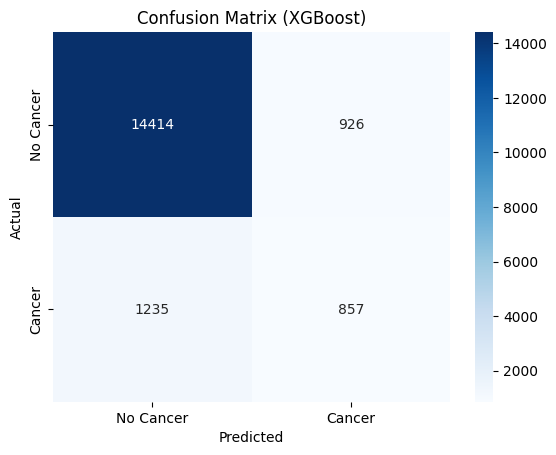

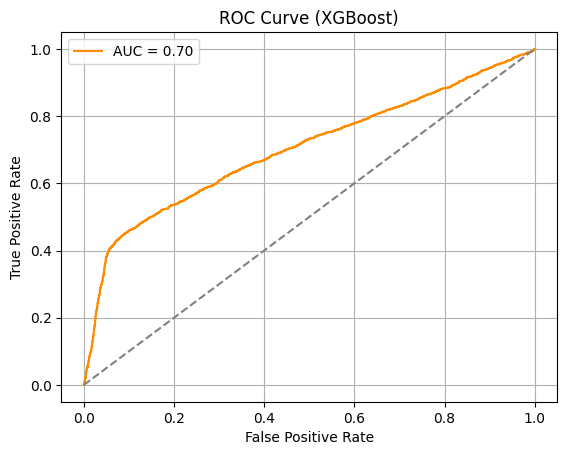

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, auc, f1_score

# 모델, 예측값, 실제값
model = clf_xgb
y_true = df_y_valid
y_pred = model.predict(df_X_valid)

# Confusion Matrix
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues', xticklabels=["No Cancer", "Cancer"], yticklabels=["No Cancer", "Cancer"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (XGBoost)")
plt.show()

# 예측 확률
y_proba = model.predict_proba(df_X_valid)[:, 1] # 양성 클래스의 확률

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_true, y_proba)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}', color='darkorange')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (XGBoost)')
plt.legend()
plt.grid(True)
plt.show()

## 3.3. Imbalanced 데이터와 비교

In [ ]:
clf_lr_imbalanced = LogisticRegression(random_state=2025).fit(df_X_train, df_y_train)
clf_rf_imbalanced = RandomForestClassifier(random_state=2025).fit(df_X_train, df_y_train)
clf_xgb_imbalanced = XGBClassifier(random_state=2025).fit(df_X_train, df_y_train)

In [ ]:
print("F1 score (LR+imbalanced):", f1_score(df_y_valid, clf_lr_imbalanced.predict(df_X_valid)))
print("F1 score (RF+imbalanced):", f1_score(df_y_valid, clf_rf_imbalanced.predict(df_X_valid)))
print("F1 score (XGB+imbalanced):", f1_score(df_y_valid, clf_xgb_imbalanced.predict(df_X_valid)))

F1 score (LR+imbalanced): 0.02421984163949697
F1 score (RF+imbalanced): 0.30835830835830835
F1 score (XGB+imbalanced): 0.31053848695077635


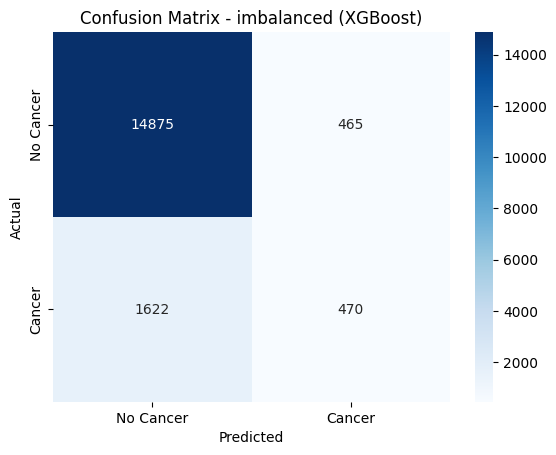

In [ ]:
# 모델, 예측값, 실제값
model = clf_xgb_imbalanced
y_true = df_y_valid
y_pred = model.predict(df_X_valid)

# Confusion Matrix
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues', xticklabels=["No Cancer", "Cancer"], yticklabels=["No Cancer", "Cancer"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - imbalanced (XGBoost)")
plt.show()

# 4. 특징 선택

In [ ]:
from sklearn.feature_selection import SequentialFeatureSelector

In [ ]:
sfs = SequentialFeatureSelector(XGBClassifier(random_state=2025), n_features_to_select=10, direction='forward', scoring='f1', cv=2, n_jobs=-1)

In [ ]:
sfs = sfs.fit(df_X_resampled, df_y_resampled)

In [ ]:
sfs.get_support()

array([ True, False, False, False, False, False, False, False, False,
        True, False,  True, False, False,  True, False, False,  True,
        True, False, False, False, False,  True, False,  True, False,
        True, False,  True, False, False, False, False])

In [ ]:
df_X_train_selected = sfs.transform(df_X_resampled)
df_X_valid_selected = sfs.transform(df_X_valid)

In [ ]:
clf_xgb_selected = XGBClassifier(random_state=2025).fit(df_X_train_selected, df_y_resampled)

In [ ]:
print("F1 score (XGB+feature_selection):", f1_score(df_y_valid, clf_xgb_selected.predict(df_X_valid_selected)))

F1 score (XGB+feature_selection): 0.4688775510204082


In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# 하이퍼 파라미터 튜닝
param_grid = {
    'n_estimators': [100, 200, 300],      # 트리 개수
    'max_depth': [3, 5, 7],               # 트리 최대 깊이
    'learning_rate': [0.01, 0.05, 0.1],   # 학습률
    'subsample': [0.7, 0.8, 1.0],         # 학습 샘플 비율
    'colsample_bytree': [0.7, 0.8, 1.0],  # 트리 만들 때 사용할 특성 비율
    'gamma': [0, 1, 5]                    # 손실 감소가 일정 이상일 때만 분할
}

xgb = XGBClassifier(random_state=2025, use_label_encoder=False, eval_metric='logloss')
search = RandomizedSearchCV(xgb, param_distributions=param_grid,
                            n_iter=100, scoring='f1', cv=5,
                            verbose=1, n_jobs=-1)

search.fit(df_X_train_selected, df_y_resampled)

best_xgb = search.best_estimator_                 # 정확도 가장 높은 모델 저장
y_pred = best_xgb.predict(df_X_valid_selected)    # 예측 수행
print("F1 score:", f1_score(df_y_valid, y_pred))

Fitting 5 folds for each of 100 candidates, totalling 500 fits


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [10:44:12] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


F1 score: 0.4764079147640791


In [ ]:
best_xgb.get_params()

{'objective': 'binary:logistic',
 'base_score': None,
 'booster': None,
 'callbacks': None,
 'colsample_bylevel': None,
 'colsample_bynode': None,
 'colsample_bytree': 0.7,
 'device': None,
 'early_stopping_rounds': None,
 'enable_categorical': False,
 'eval_metric': 'logloss',
 'feature_types': None,
 'gamma': 1,
 'grow_policy': None,
 'importance_type': None,
 'interaction_constraints': None,
 'learning_rate': 0.1,
 'max_bin': None,
 'max_cat_threshold': None,
 'max_cat_to_onehot': None,
 'max_delta_step': None,
 'max_depth': 7,
 'max_leaves': None,
 'min_child_weight': None,
 'missing': nan,
 'monotone_constraints': None,
 'multi_strategy': None,
 'n_estimators': 200,
 'n_jobs': None,
 'num_parallel_tree': None,
 'random_state': 2025,
 'reg_alpha': None,
 'reg_lambda': None,
 'sampling_method': None,
 'scale_pos_weight': None,
 'subsample': 1.0,
 'tree_method': None,
 'validate_parameters': None,
 'verbosity': None,
 'use_label_encoder': False}

# 5. 시험 데이터 불러오기

## 5.1. CSV 파일을 Pandas 데이터프레임으로 불러오기

In [ ]:
## 파일 경로 확인
filepath_test = os.path.join(dirname, 'test.csv')
print(os.path.exists(filepath_test))

True


In [ ]:
## CSV 파일 불러오기
df_test = pd.read_csv(filepath_test)

In [ ]:
## 시험 데이터 확인
print(df_test.shape)
df_test.head()

(46204, 15)


,ID,Age,Gender,Country,Race,Family_Background,Radiation_History,Iodine_Deficiency,Smoke,Weight_Risk,Diabetes,Nodule_Size,TSH_Result,T4_Result,T3_Result
0,TEST_00000,53,M,NGA,CAU,Negative,Unexposed,Sufficient,Non-Smoker,Not Obese,No,2.940678,6.434501,9.227958,2.733846
1,TEST_00001,46,M,KOR,MDE,Negative,Unexposed,Deficient,Smoker,Obese,No,3.450129,4.729535,5.937664,0.775012
2,TEST_00002,78,F,IND,ASN,Negative,Exposed,Sufficient,Non-Smoker,Obese,No,4.680720,5.663475,10.455964,1.259896
3,TEST_00003,69,F,KOR,CAU,Negative,Unexposed,Sufficient,Non-Smoker,Not Obese,No,4.280588,7.473752,8.785335,2.826138
4,TEST_00004,77,F,KOR,CAU,Positive,Unexposed,Sufficient,Non-Smoker,Obese,No,3.380094,7.099987,8.737063,3.453563


## 5.2. 데이터 전처리하기

In [ ]:
df_test_category = pd.DataFrame(enc.transform(df_test.loc[:,categorical_columns]).toarray(), columns=enc.get_feature_names_out(categorical_columns))
df_test_numeric = pd.DataFrame(scaler.transform(df_test.loc[:,numeric_columns]), columns=numeric_columns)
df_test_preprocessed = pd.concat([df_test_numeric, df_test_category], axis=1)

In [ ]:
## 정수형 데이터로 변환된 결과 확인
df_test_preprocessed

,Age,Nodule_Size,TSH_Result,T4_Result,T3_Result,Gender_F,Gender_M,Country_BRA,Country_CHN,Country_DEU,...,Radiation_History_Exposed,Radiation_History_Unexposed,Iodine_Deficiency_Deficient,Iodine_Deficiency_Sufficient,Smoke_Non-Smoker,Smoke_Smoker,Weight_Risk_Not Obese,Weight_Risk_Obese,Diabetes_No,Diabetes_Yes
0,0.527027,0.588136,0.639849,0.630394,0.744615,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0
1,0.432432,0.690026,0.467630,0.191689,0.091671,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0
2,0.864865,0.936144,0.561967,0.794129,0.253299,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0
3,0.743243,0.856118,0.744823,0.571378,0.775379,1.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0
4,0.851351,0.676019,0.707069,0.564942,0.984521,1.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46199,0.040541,0.010113,0.732954,0.430552,0.179375,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0
46200,0.310811,0.602177,0.392111,0.298662,0.584222,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0
46201,0.054054,0.956148,0.307296,0.984414,0.181398,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0
46202,0.337838,0.084167,0.346965,0.505927,0.424926,0.0,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0


In [ ]:
## 속성 순서 동일한지 체크
df_test_preprocessed.columns == df_X_resampled.columns

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True])

## 5.3. 시험데이터의 레이블 예측하기

In [ ]:
prediction = clf_xgb.predict(df_test_preprocessed)

In [ ]:
## 예측 결과 살펴보기
print(prediction.shape)
print("Positive (prediction):", prediction.sum())
print("Negative (prediction):", prediction.shape[0] - prediction.sum())

(46204,)
Positive (prediction): 5439
Negative (prediction): 40765


## 4.4. 제출용 CSV 파일 만들기

In [ ]:
df_submission = df_test.loc[:,'ID'].to_frame()

In [ ]:
df_submission.loc[:,'Cancer'] = prediction

In [ ]:
## 제출용 파일 확인
print(df_submission.shape)
df_submission

(46204, 2)


,ID,Cancer
0,TEST_00000,1
1,TEST_00001,0
2,TEST_00002,0
3,TEST_00003,0
4,TEST_00004,0
...,...,...
46199,TEST_46199,0
46200,TEST_46200,0
46201,TEST_46201,0
46202,TEST_46202,0


In [ ]:
## CSV 저장
#df_submission.to_csv(os.path.join(dirname, 'submission_last.csv'), index=False)